# Figure 6 — why L-BFGS fails the Toffoli at spread $0.01\pi$

`hyperparameter_search.ipynb` leaves one result unexplained. At the narrowest initial
spread `LBFGS` reaches the target on 2 of 10 seeds and spends the whole 200-iteration
budget on the other eight, and no setting of `memory` repairs it. Both of the other
methods converge on the same pulses in tens of iterations.

The cause is the trade the user guide already names. The curvature condition rejects
any pair with $s^\intercal y\le0$, which is what keeps the implicit $H_m$ positive
definite and the two-loop recursion a descent method without ever forming a matrix.
But this landscape is **about half negative-curvature**, and a positive-definite
operator cannot point along the directions that matter. `NewtonSaddleFree` is the
control that isolates it: it differs from L-BFGS essentially in inverting
$\lvert\lambda\rvert$ instead of excluding $\lambda<0$.

In [1]:
from common import *

In [2]:
#: The failing corner of `hyperparameter_search.ipynb`. `3`, `MAX_STEPS`,
#: `PRECISION`, `SPREAD` and `GEOPE_MAX_STEP` all come from `common`, which already
#: carries the values that sweep used.
L_STEPS = 120
MEMORY = 10

#: Seed 1 fails at `LBFGS(10)` in the sweep (200 iterations, $1-F\approx10^{-7}$);
#: the other two methods converge from the same pulse.
SEED = 1

#: Iterations along the L-BFGS trajectory to diagonalise. Early, middle and late, so
#: the right panel shows the indefiniteness is the shape of the landscape rather than
#: a transient of the first few steps.
SPECTRUM_STEPS = (5, 25, 100, 195)


def infidelity_trace(optimiser, **options):
    """Run one optimiser from `PULSE` and return its `History`.

    ``record`` is called once before the loop so index 0 is the initial pulse, which
    is what puts all three traces on the same iteration axis.
    """
    optimiser.init(init_parameters=PULSE)
    optimiser.history.reset()
    optimiser.history.record(optimiser)  # step 0, after the re-init
    optimiser.optimize(**options)
    return optimiser.history


params = make_parameters(3, L_STEPS, "CCX", spread=SPREAD)
manifold = params.manifold
N_PARAMS = params.free().size
PULSE = random_pulse(params, np.random.default_rng(SEED), SPREAD)

HISTORIES = {
    "LBFGS": infidelity_trace(
        Grape(params, precision=PRECISION, history=History()),
        max_steps=MAX_STEPS, optimizer=LBFGS(MEMORY),
    ),
    "NewtonSaddleFree": infidelity_trace(
        Grape(params, precision=PRECISION, history=History()),
        max_steps=MAX_STEPS, optimizer=NewtonSaddleFree(rcond=1e-8),
    ),
    "GEOPE": infidelity_trace(
        Geope(params, history=History()),
        max_steps=MAX_STEPS, precision=PRECISION,
        line_search=Armijo(), max_step_size=GEOPE_MAX_STEP,
    ),
}
#: Keyed by the optimiser's class name, so `COLOURS` and `LABELS` from `common` index
#: straight into it and this figure agrees with Figure 1 on which colour is which
#: method.
TRACES = {
    method: 1.0 - np.asarray(history.fidelities, dtype=float)
    for method, history in HISTORIES.items()
}

print(f"P = {N_PARAMS} free parameters, seed {SEED}, identical initial pulse\n")
print(f"{'method':20s} {'iterations':>11s} {'final 1-F':>12s}   outcome")
for method, trace in TRACES.items():
    converged = trace[-1] < 1.0 - PRECISION
    print(f"{LABELS[method]:20s} {len(trace) - 1:11d} {trace[-1]:12.3e}   "
          f"{'converged' if converged else 'budget exhausted'}")

P = 1080 free parameters, seed 1, identical initial pulse

method                iterations    final 1-F   outcome
L-BFGS                       200    9.785e-08   budget exhausted
Newton: SFN                   28    4.285e-14   converged
GEOPE                         26    7.256e-11   converged


## The Hessian along the L-BFGS trajectory

Diagonalise the dense $(P,P)$ cost Hessian at four points on the L-BFGS path. Two
quantities matter, and the second is what makes the first consequential:

- the **sign structure** of the spectrum, i.e. how much of it is negative;
- **`neg_fraction`**, the share of $\lVert p_{\mathrm{SF}}\rVert^2$ carried by
  eigenvectors with $\lambda<0$, where $p_{\mathrm{SF}} = \lvert H\rvert^{+}\nabla C$
  is the saddle-free step. That is the part of the working step a positive-definite
  $H_m$ **cannot point along at all**, whatever `memory` it is given.

`ctx.cost_hessian` is direction-free, so no `set_direction` is needed, and
`manifold.hessian` is a jitted `cached_property`, so only the first call compiles.

In [3]:
def hessian_spectrum(pulse_row):
    """``(eigenvalues, neg_fraction, grad_norm)`` at one pulse on the trajectory.

    `History` logs full-basis parameters, so the proj+drift columns have to be
    selected back out with `Parameters.free` before the manifold will accept them.
    """
    free = params.free(pulse_row)
    _value, gradient = manifold.value_and_grad(free)
    flat_gradient = np.asarray(jnp.real(gradient)).ravel()
    hessian = np.asarray(jnp.real(manifold.hessian(free)))

    eigenvalues, basis = np.linalg.eigh(hessian)
    # Resolve the saddle-free step in the curvature eigenbasis. Its weight on
    # lambda < 0 is exactly what a positive-definite approximation has to leave out.
    magnitude = np.abs(eigenvalues)
    keep = magnitude > 1e-8 * magnitude.max()
    projected = basis.T @ flat_gradient
    saddle_free = np.where(keep, projected / np.where(keep, magnitude, 1.0), 0.0)
    total = max(float((saddle_free**2).sum()), 1e-300)
    negative = eigenvalues < 0
    return (
        eigenvalues,
        float((saddle_free[negative] ** 2).sum() / total),
        float(np.linalg.norm(flat_gradient)),
    )


logged_pulses = np.asarray(HISTORIES["LBFGS"].parameters)
SPECTRA = {step: hessian_spectrum(logged_pulses[step]) for step in SPECTRUM_STEPS}

print(f"L-BFGS trajectory, seed {SEED}, P = {N_PARAMS}\n")
print(f"{'iter':>5s} {'1-F':>10s} {'|grad|':>10s} {'lam_min':>11s} {'lam_max':>9s} "
      f"{'#(lam<0)':>9s} {'frac':>6s} {'neg_frac':>9s}")
for step, (eigenvalues, neg_fraction, grad_norm) in SPECTRA.items():
    n_negative = int((eigenvalues < 0).sum())
    print(f"{step:5d} {TRACES['LBFGS'][step]:10.2e} {grad_norm:10.2e} "
          f"{eigenvalues.min():11.3e} {eigenvalues.max():9.2f} {n_negative:9d} "
          f"{n_negative / N_PARAMS:6.2f} {neg_fraction:9.3f}")

L-BFGS trajectory, seed 1, P = 1080

 iter        1-F     |grad|     lam_min   lam_max  #(lam<0)   frac  neg_frac
    5   8.38e-02   2.78e+00  -4.765e+00    113.40       449   0.42     0.293
   25   6.69e-05   1.75e-02  -4.838e-02    119.26       528   0.49     0.525
  100   1.17e-06   6.31e-04  -2.352e-03    119.49       566   0.52     0.602
  195   1.01e-07   1.50e-04  -5.964e-04    119.51       548   0.51     0.569


## Figure

**(a)** All three methods from one initial pulse. **(b)** The sorted Hessian spectrum
at four points along the L-BFGS path, on a symmetric-log axis so both signs are
visible, with the $\lambda<0$ half shaded. About half of the 1080 eigenvalues are
negative at every one of them, and the table above gives the share of the saddle-free
step that lives there.

figures/fig6_lbfgs_negative_curvature_L120.pdf


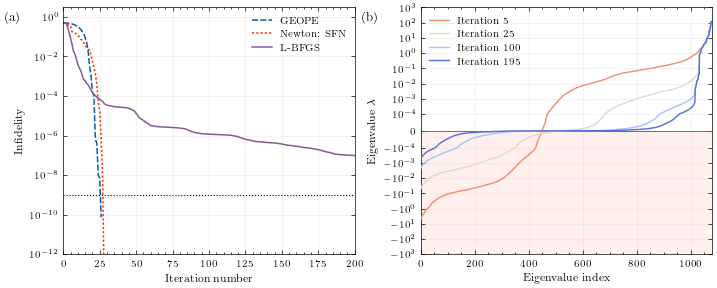

In [4]:
#: Dash patterns per method; the colours are `COLOURS` from `common`, so a method
#: keeps the same colour it has in Figure 1.
DASHES = {
    "LBFGS": "solid",
    "GEOPE": (0, (4, 1.4)),
    "NewtonSaddleFree": (0, (1.4, 1.4)),
}
#: Light to dark with the iteration, so the right panel reads without the legend.
SPECTRUM_COLOURS = dict(
    zip(SPECTRUM_STEPS, plt.cm.coolwarm(np.linspace(0.78, 0.08, len(SPECTRUM_STEPS))))
)

fig, (ax_run, ax_spectrum) = plt.subplots(1, 2, figsize=(TWO_COLUMN, 2.9))

# ---- (a) the three trajectories
for method in ("GEOPE", "NewtonSaddleFree", "LBFGS"):
    ax_run.plot(
        TRACES[method],
        color=COLOURS[method],
        ls=DASHES[method],
        lw=1.1,
        label=LABELS[method],
    )
ax_run.axhline(1 - PRECISION, color="black", ls=":", lw=0.8)
ax_run.set_yscale("log")
ax_run.set_ylim(1e-12, 3.0)
ax_run.set_xlim(0, MAX_STEPS)
ax_run.set_xlabel("Iteration number")
ax_run.set_ylabel(r"Infidelity")
ax_run.grid(alpha=0.25, which="major", lw=0.4)
ax_run.legend(loc="upper right", frameon=False)

# ---- (b) the curvature it discards
ax_spectrum.axhspan(-1e3, 0.0, color=COLOURS["NewtonSaddleFree"], alpha=0.07, lw=0,
                    zorder=0)
for step, (eigenvalues, _neg_fraction, _grad) in SPECTRA.items():
    ax_spectrum.plot(
        np.sort(eigenvalues),
        color=SPECTRUM_COLOURS[step],
        lw=1.0,
        zorder=3,
        label=rf"Iteration {step}",
    )
ax_spectrum.axhline(0.0, color="0.35", lw=0.6, zorder=2)
# `symlog` keeps both signs on one axis.
ax_spectrum.set_yscale("symlog", linthresh=1e-4)
ax_spectrum.set_ylim(-1e3, 1e3)
ax_spectrum.set_xlim(0, N_PARAMS)
ax_spectrum.set_xlabel(r"Eigenvalue index")
ax_spectrum.set_ylabel(r"Eigenvalue $\lambda$")
ax_spectrum.grid(alpha=0.25, which="major", lw=0.4)
ax_spectrum.legend(loc="upper left", frameon=False)

panel_label(ax_run, "a")
panel_label(ax_spectrum, "b")
fig.tight_layout(pad=0.5)
print(save_figure(fig, f"fig6_lbfgs_negative_curvature_L{L_STEPS}"))
plt.show()

## Conclusion

The inverse-Hessian approximation is what fails, and the inaccuracy is **structural
rather than statistical**: not that ten curvature pairs estimate $H^{-1}$ badly, but
that a positive-definite $H_m$ cannot represent a step of which about half lies in the
negative-curvature subspace. The curvature condition that guarantees L-BFGS is a
descent method is the same thing that makes it blind here, so no `memory` fixes it —
which is what the sweep found when every value from $m=2$ to $m=100$ gave the same
median. `NewtonSaddleFree` converges from the same pulse in ~26 iterations, which is
the measurement behind the user guide's advice to prefer it for gate synthesis.